# Cardiovascular Risk Analysis - Classification with 5 Algorithms

**Target variable:** `cardio` (1 = cardiovascular disease present, 0 = absent)
**Dataset:** `HeartFailureDataset.csv` (~70,000 patient records)

**Models (from the assignment list):** Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base estimator), MLP Neural Network.

**Pipeline:** load -> inspect -> missing values / duplicates -> outlier detection and treatment -> encoding -> train/test split -> scaling -> PCA -> hyper-parameter tuning and training -> evaluation (table, ROC-AUC, confusion matrices, tree) -> inference.

> Place `HeartFailureDataset.csv` in the same folder as this notebook. Requires scikit-learn >= 1.2.

## 1. Load the dataset

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_PATH = "HeartFailureDataset.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62,110,80,1,1,0,0,1,0
1,1,20228,1,156,85,140,90,3,1,0,0,1,1
2,2,18857,1,165,64,130,70,3,1,0,0,0,1
3,3,17623,2,169,82,150,100,1,1,0,0,1,1
4,4,17474,1,156,56,100,60,1,1,0,0,0,0


## 2. Data inspection and cleaning

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (70000, 13)

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           70000 non-null  int64
 1   age          70000 non-null  int64
 2   gender       70000 non-null  int64
 3   height       70000 non-null  int64
 4   weight       70000 non-null  int64
 5   ap_hi        70000 non-null  int64
 6   ap_lo        70000 non-null  int64
 7   cholesterol  70000 non-null  int64
 8   gluc         70000 non-null  int64
 9   smoke        70000 non-null  int64
 10  alco         70000 non-null  int64
 11  active       70000 non-null  int64
 12  cardio       70000 non-null  int64
dtypes: int64(13)
memory usage: 6.9 MB


In [4]:
display(df.describe().T)
print("Duplicate rows :", df.duplicated().sum())
print()
print("Missing values per column:")
print(df.isnull().sum())

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205543,14.395829,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817714,154.011381,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


Duplicate rows : 0

Missing values per column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


**Observation:** There are no missing values and no duplicate rows. However, `describe()` already shows impossible values: `ap_hi` (systolic blood pressure) ranges from -150 to 16,020 and `ap_lo` from -70 to 11,000, and there are extreme heights and weights (55 cm, 250 cm, 10 kg, 200 kg). These are handled in the outlier step. These are handled in the outlier step.

### 2.1 Handling duplicates / missing values and light feature engineering

In [5]:
# Duplicates
n_before = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {n_before - len(df)}")

# `id` is only a row identifier, it carries no medical information
df = df.drop(columns=["id"])

# Missing values: median for numeric columns, mode otherwise (nothing to fill here, kept for robustness)
for c in df.columns:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median() if pd.api.types.is_numeric_dtype(df[c]) else df[c].mode()[0])
print("Remaining missing values:", int(df.isnull().sum().sum()))

# Feature engineering: age is stored in days -> convert to years; add Body-Mass-Index
df["age_years"] = (df["age"] / 365.25).round(1)
df = df.drop(columns=["age"])
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

# Quick look at physiologically impossible blood-pressure readings
print()
print("ap_hi > 250          :", (df["ap_hi"] > 250).sum())
print("ap_hi < 60           :", (df["ap_hi"] < 60).sum())
print("ap_lo > 200          :", (df["ap_lo"] > 200).sum())
print("ap_hi <= ap_lo       :", (df["ap_hi"] <= df["ap_lo"]).sum())
print("Shape now            :", df.shape)

Duplicates removed: 0
Remaining missing values: 0

ap_hi > 250          : 40
ap_hi < 60           : 188
ap_lo > 200          : 953
ap_hi <= ap_lo       : 1236
Shape now            : (70000, 13)


## 3. Outlier detection (IQR method) and treatment

In [6]:
cont_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]

def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in cont_cols:
    lo, hi = iqr_bounds(df[c])
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"feature": c, "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
                 "n_outliers": n_out, "pct_outliers": round(100 * n_out / len(df), 2)})
outlier_table = pd.DataFrame(rows)
outlier_table

,feature,lower_bound,upper_bound,n_outliers,pct_outliers
0,age_years,33.40,73.40,4,0.01
1,height,142.50,186.50,519,0.74
2,weight,39.50,107.50,1819,2.60
3,ap_hi,90.00,170.00,1435,2.05
4,ap_lo,65.00,105.00,4632,6.62
5,bmi,14.35,39.74,1995,2.85


**Boxplots BEFORE outlier treatment**

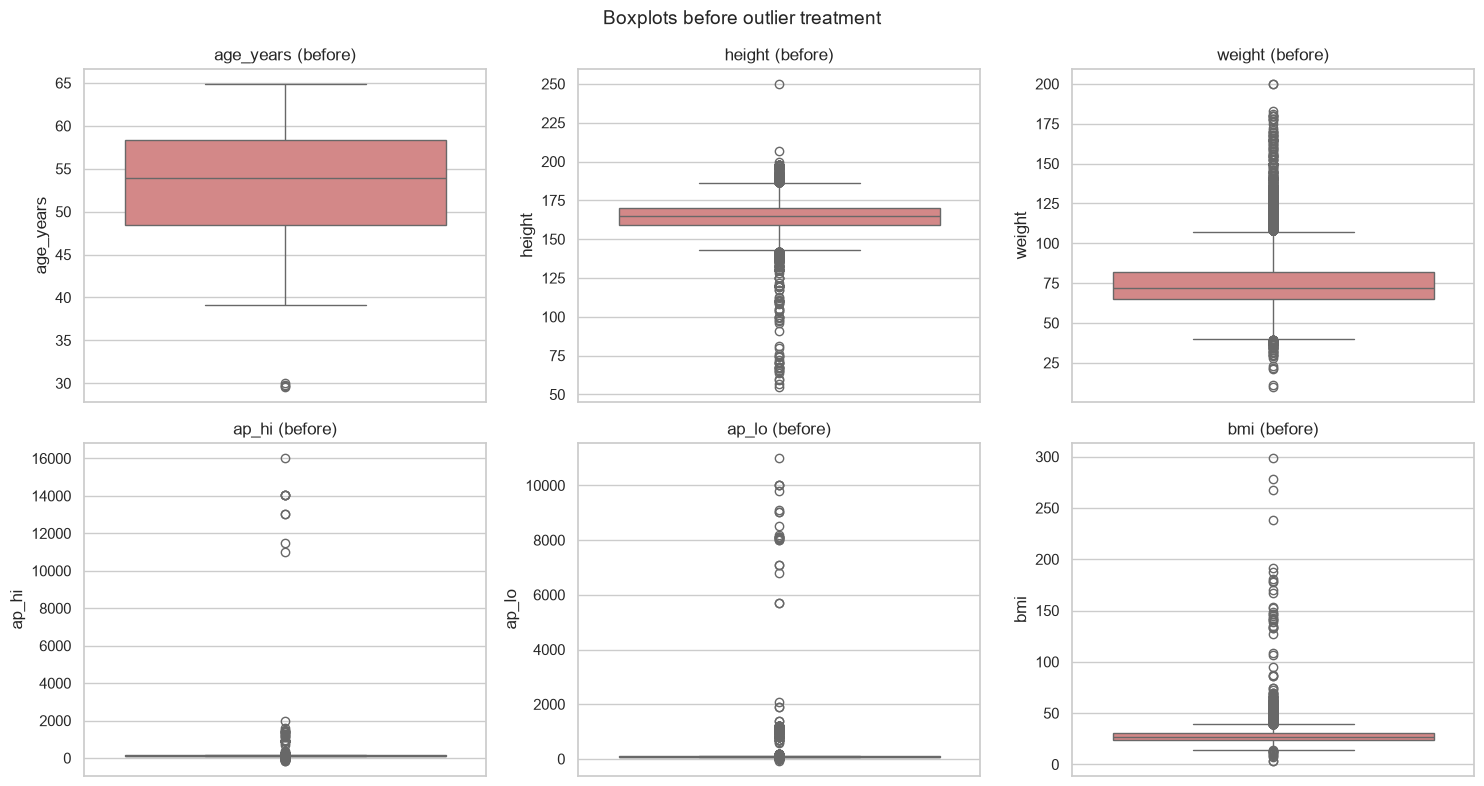

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df[c], ax=ax, color="#e07b7b")
    ax.set_title(f"{c} (before)")
plt.suptitle("Boxplots before outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

**Treatment:** values outside the IQR fences are **capped (winsorised)** at the fence rather than deleted. This keeps all ~70,000 observations and removes the influence of impossible values.

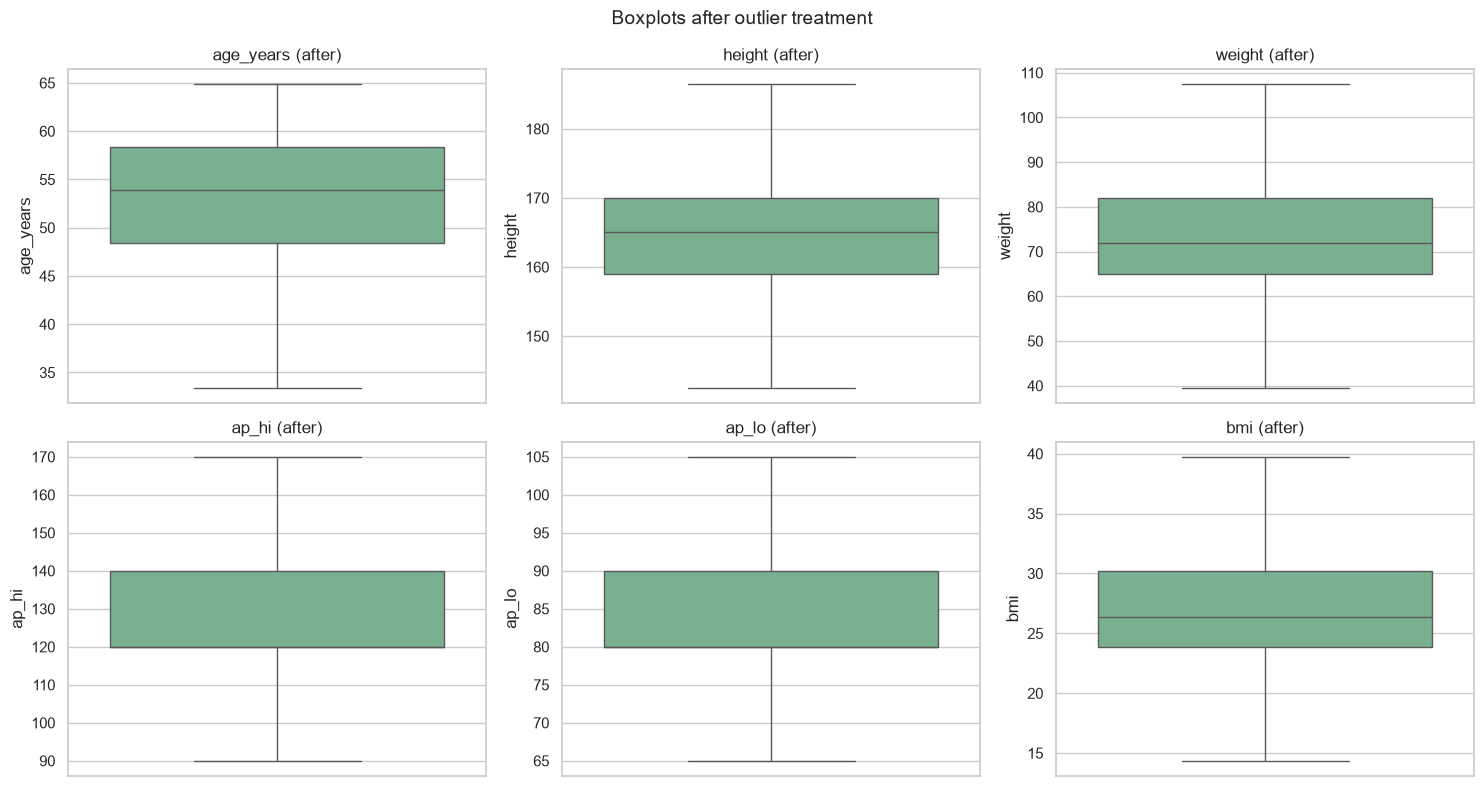

In [8]:
df_clean = df.copy()
for c in cont_cols:
    lo, hi = iqr_bounds(df[c])          # fences computed on the original data
    df_clean[c] = df_clean[c].clip(lower=lo, upper=hi)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df_clean[c], ax=ax, color="#6fb98f")
    ax.set_title(f"{c} (after)")
plt.suptitle("Boxplots after outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

### 3.1 Shape and `describe()` after outlier treatment

In [9]:
print("Shape after treatment:", df_clean.shape)
display(df_clean.describe().T)

Shape after treatment: (70000, 13)


,count,mean,std,min,25%,50%,75%,max
gender,70000.0,1.349571,0.476838,1.000000,1.000000,1.000000,2.000000,2.000000
height,70000.0,164.407179,7.825729,142.500000,159.000000,165.000000,170.000000,186.500000
weight,70000.0,73.925521,13.442415,39.500000,65.000000,72.000000,82.000000,107.500000
ap_hi,70000.0,126.712757,16.385671,90.000000,120.000000,120.000000,140.000000,170.000000
ap_lo,70000.0,81.779500,9.062702,65.000000,80.000000,80.000000,90.000000,105.000000
cholesterol,70000.0,1.366871,0.680250,1.000000,1.000000,1.000000,2.000000,3.000000
gluc,70000.0,1.226457,0.572270,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,70000.0,0.088129,0.283484,0.000000,0.000000,0.000000,0.000000,1.000000
alco,70000.0,0.053771,0.225568,0.000000,0.000000,0.000000,0.000000,1.000000
active,70000.0,0.803729,0.397179,0.000000,1.000000,1.000000,1.000000,1.000000


## 4. Encoding, EDA, split, scaling and dimensionality reduction

In [10]:
# --- Encoding ---------------------------------------------------------------
# gender: 1/2 -> 0/1 (binary encoding)
df_clean["gender"] = df_clean["gender"].map({1: 0, 2: 1})
# cholesterol and gluc are ORDINAL (1 = normal, 2 = above normal, 3 = well above normal)
# -> the existing integer order is already the correct ordinal encoding.
# any remaining text columns (none in this dataset) would be one-hot encoded
obj_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
if obj_cols:
    df_clean = pd.get_dummies(df_clean, columns=obj_cols, drop_first=True)

print("Non-numeric columns left:", df_clean.select_dtypes(exclude="number").columns.tolist())
df_clean.dtypes

Non-numeric columns left: []


gender           int64
height         float64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
age_years      float64
bmi            float64
dtype: object

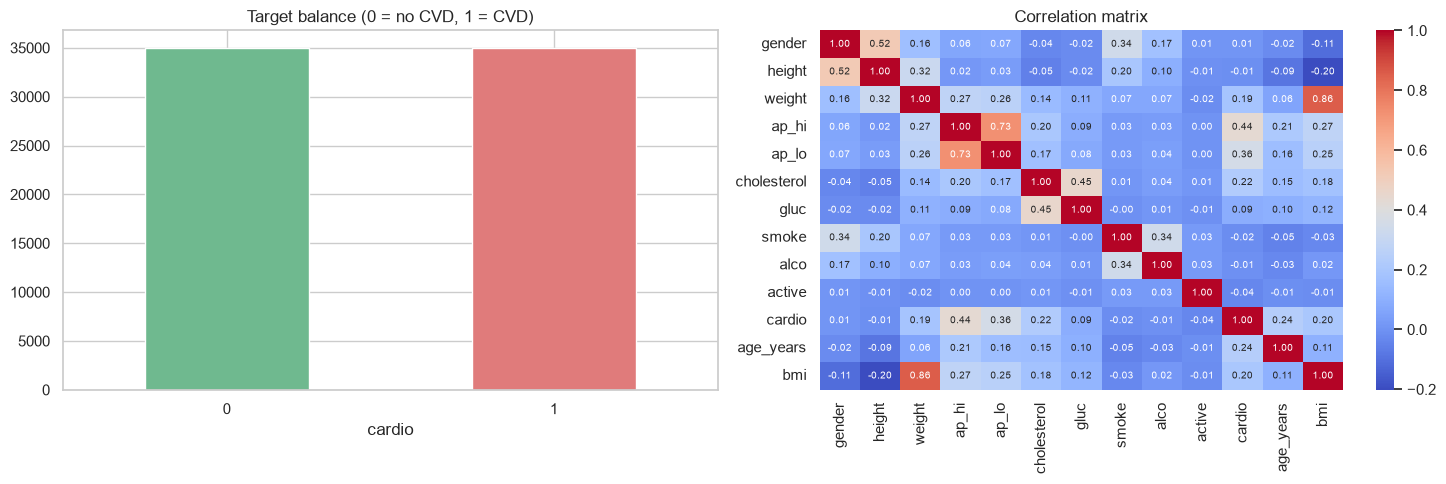

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_clean["cardio"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#6fb98f", "#e07b7b"])
axes[0].set_title("Target balance (0 = no CVD, 1 = CVD)")
axes[0].set_xticklabels(["0", "1"], rotation=0)
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.show()

### 4.1 Train / test split
Stratified 80/20 split so both sets keep the same class ratio. The split is done **before** scaling and PCA, and the scaler and PCA are fitted on the training data only, so no information from the test set leaks into training.

In [12]:
X = df_clean.drop(columns="cardio")
y = df_clean["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())

X_train: (56000, 12) | X_test: (14000, 12)
Train class ratio: {0: 0.5, 1: 0.5}


### 4.2 Feature scaling (StandardScaler) and dimensionality reduction (PCA)
PCA is variance based, so the features are standardised first. The number of components is chosen to retain **95 % of the variance**.

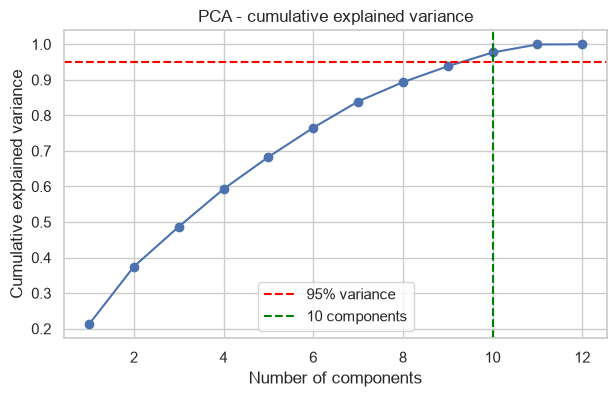

Features before PCA: 12  ->  after PCA: 10
Variance retained  : 0.977


In [13]:
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_sc)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.95) + 1)

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(X_train_sc)
X_train_pca = pca.transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="red", ls="--", label="95% variance")
plt.axvline(n_comp, color="green", ls="--", label=f"{n_comp} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA - cumulative explained variance"); plt.legend()
plt.show()

print(f"Features before PCA: {X_train_sc.shape[1]}  ->  after PCA: {X_train_pca.shape[1]}")
print(f"Variance retained  : {pca.explained_variance_ratio_.sum():.3f}")

## 5. Model training with hyper-parameter tuning
Each model is tuned with `GridSearchCV` (3-fold, scored on ROC-AUC) on a stratified 15,000-row sample of the training set to keep run-time reasonable. The best parameters are then used to **refit the model on the full training set**, and the test set is only used for the final evaluation.

In [14]:
results = {}

def tune_and_fit(name, estimator, param_grid, search_size=15000):
    t0 = time.time()
    X_sub, _, y_sub, _ = train_test_split(X_train_pca, y_train, train_size=search_size,
                                          stratify=y_train, random_state=RANDOM_STATE)
    gs = GridSearchCV(estimator, param_grid, cv=3, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_sub, y_sub)

    best = clone(estimator).set_params(**gs.best_params_)
    best.fit(X_train_pca, y_train)

    results[name] = {
        "model": best,
        "best_params": gs.best_params_,
        "cv_auc": gs.best_score_,
        "y_pred": best.predict(X_test_pca),
        "y_prob": best.predict_proba(X_test_pca)[:, 1],
        "train_acc": accuracy_score(y_train, best.predict(X_train_pca)),
        "time_s": time.time() - t0,
    }
    print(f"{name:<18} best params: {gs.best_params_}")
    print(f"{'':<18} CV ROC-AUC = {gs.best_score_:.4f} | total time = {time.time() - t0:.0f}s")

### 5.1 Random Forest (tuned: `n_estimators`, `max_depth`)

In [15]:
tune_and_fit(
    "Random Forest",
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [100, 200, 300], "max_depth": [8, 12, 16]})

Random Forest      best params: {'max_depth': 8, 'n_estimators': 300}
                   CV ROC-AUC = 0.7903 | total time = 113s


### 5.2 AdaBoost (tuned: `n_estimators`, `learning_rate`)

In [16]:
tune_and_fit(
    "AdaBoost",
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]})

AdaBoost           best params: {'learning_rate': 0.5, 'n_estimators': 200}
                   CV ROC-AUC = 0.7844 | total time = 75s


### 5.3 Gradient Boosting (scikit-learn GBM)

In [17]:
tune_and_fit(
    "Gradient Boosting",
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 4]})

Gradient Boosting  best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}
                   CV ROC-AUC = 0.7910 | total time = 148s


### 5.4 Bagging (Decision Tree as base estimator)

In [18]:
tune_and_fit(
    "Bagging",
    BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                      random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [50, 100], "estimator__max_depth": [6, 8, 12]})

Bagging            best params: {'estimator__max_depth': 8, 'n_estimators': 100}
                   CV ROC-AUC = 0.7879 | total time = 63s


### 5.5 MLP Neural Network (tuned: `hidden_layer_sizes`, `activation`)

In [19]:
tune_and_fit(
    "MLP Neural Network",
    MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
    {"hidden_layer_sizes": [(50,), (100,), (64, 32)], "activation": ["relu", "tanh"]})

MLP Neural Network best params: {'activation': 'relu', 'hidden_layer_sizes': (64, 32)}
                   CV ROC-AUC = 0.7949 | total time = 35s


## 6. Results

### 6.1 Evaluation metrics table (test set)

In [20]:
rows = []
for name, r in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, r["y_pred"]),
        "Precision": precision_score(y_test, r["y_pred"]),
        "Recall": recall_score(y_test, r["y_pred"]),
        "F1-score": f1_score(y_test, r["y_pred"]),
        "ROC-AUC": roc_auc_score(y_test, r["y_prob"]),
        "Train Accuracy": r["train_acc"],
        "CV ROC-AUC": r["cv_auc"],
        "Time (s)": r["time_s"],
    })
results_df = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
results_df["Overfit gap"] = results_df["Train Accuracy"] - results_df["Accuracy"]
results_df.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train Accuracy,CV ROC-AUC,Time (s),Overfit gap
Model,,,,,,,,,
MLP Neural Network,0.7237,0.7354,0.6984,0.7164,0.7893,0.7307,0.7949,35.4978,0.0070
Gradient Boosting,0.7220,0.7417,0.6808,0.7099,0.7883,0.7354,0.7910,148.1465,0.0134
Random Forest,0.7224,0.7432,0.6790,0.7096,0.7852,0.7408,0.7903,113.2413,0.0185
Bagging,0.7184,0.7424,0.6682,0.7034,0.7852,0.7428,0.7879,62.8500,0.0245
AdaBoost,0.7166,0.7231,0.7014,0.7121,0.7778,0.7230,0.7844,75.1741,0.0064


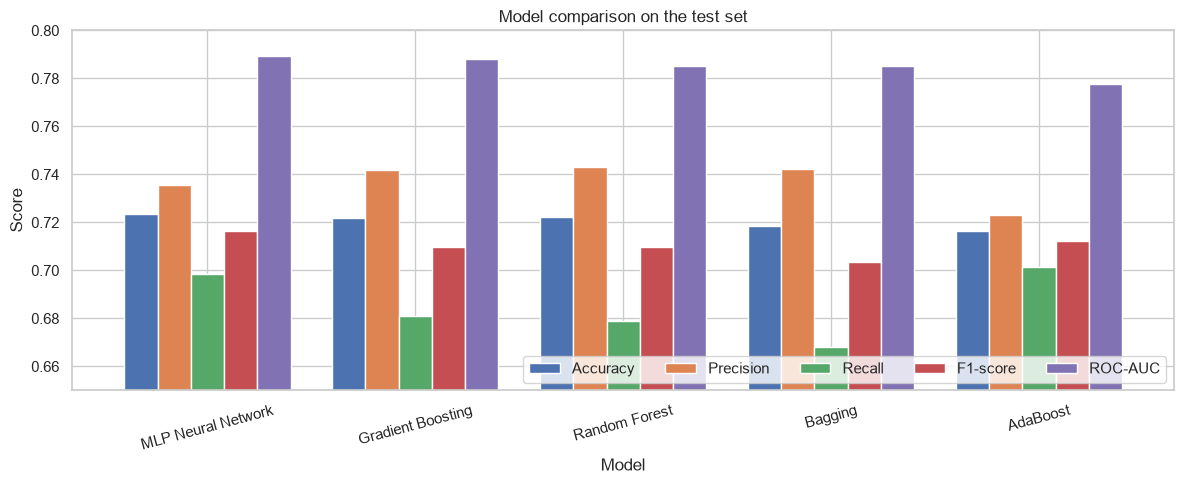

In [21]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = results_df[metrics].plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_ylim(0.65, 0.80)
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

### 6.2 ROC-AUC curves

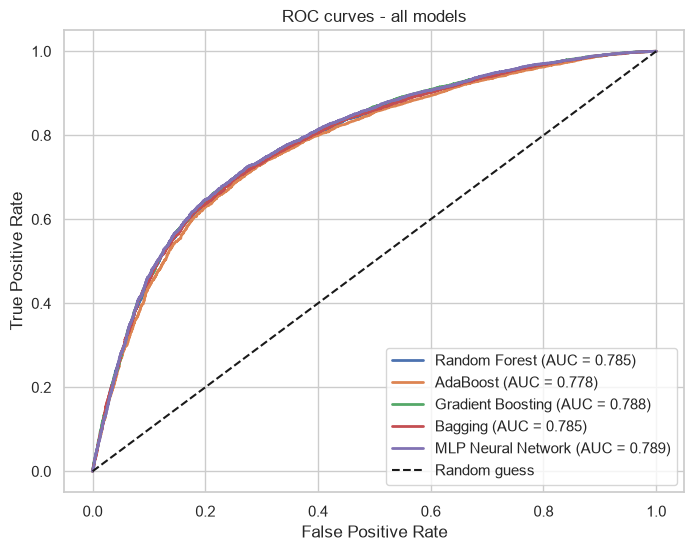

In [22]:
plt.figure(figsize=(8, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_prob"])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, r['y_prob']):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves - all models")
plt.legend(loc="lower right")
plt.show()

### 6.3 Confusion matrices

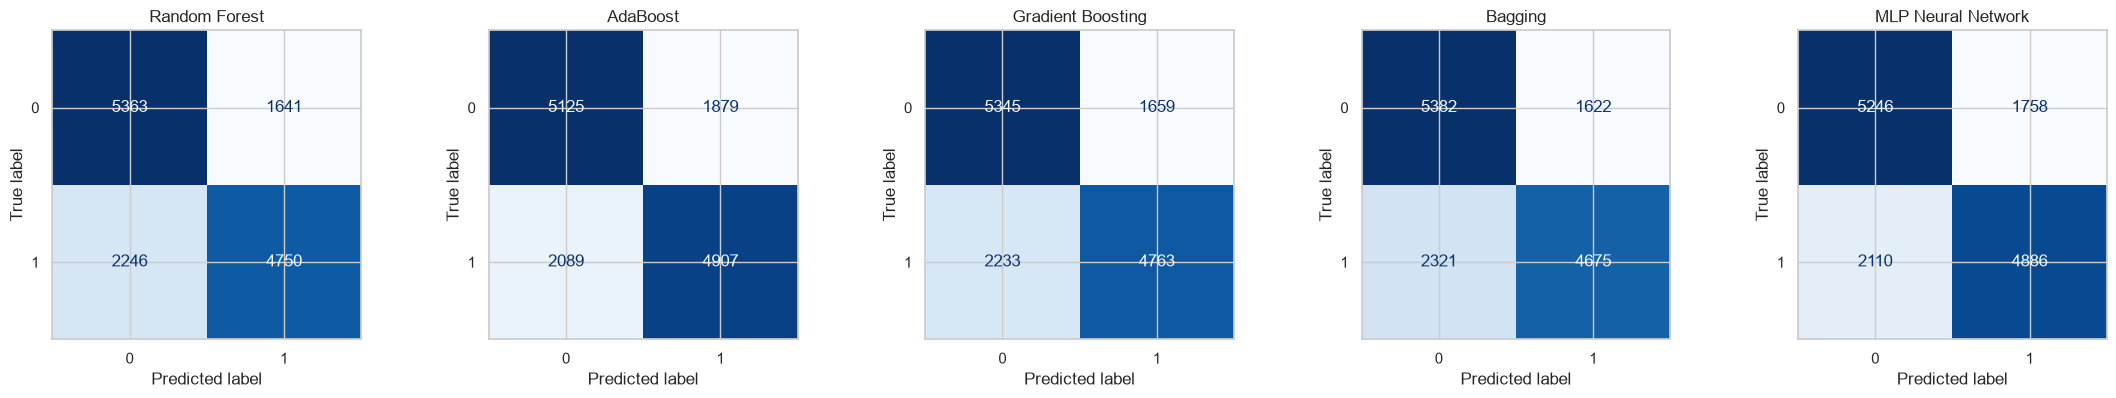

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, r) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, r["y_pred"], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 6.4 Decision tree and feature importance
The models above were trained on PCA components (PC1, PC2, ...), which are hard to read medically. For interpretation, this section uses the **original scaled features**:
a depth-3 decision tree (visual) and Random Forest feature importances (using the tuned Random Forest parameters).

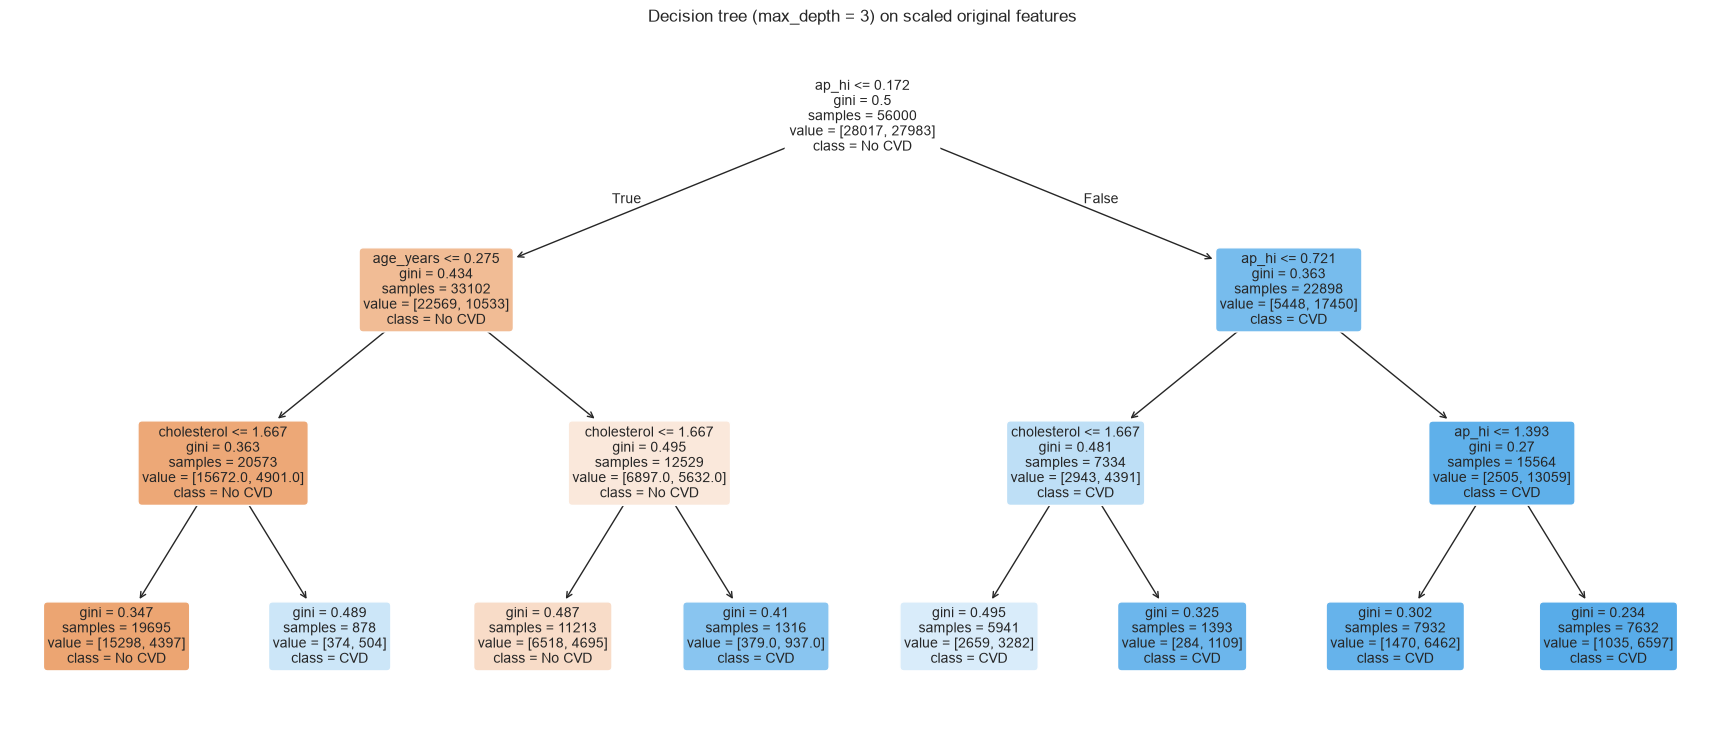

Depth-3 tree test accuracy: 0.7212


In [24]:
feature_names = list(X.columns)

dt = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train_sc, y_train)
plt.figure(figsize=(22, 9))
plot_tree(dt, feature_names=feature_names, class_names=["No CVD", "CVD"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision tree (max_depth = 3) on scaled original features")
plt.show()
print(f"Depth-3 tree test accuracy: {dt.score(X_test_sc, y_test):.4f}")

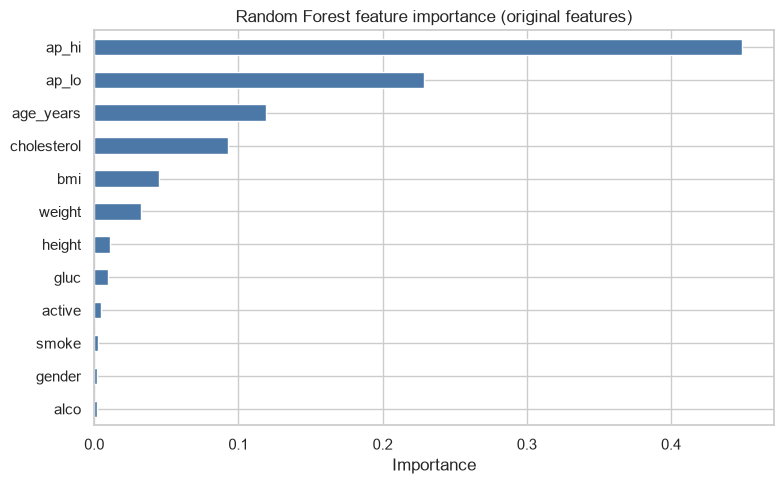

ap_hi          0.4489
ap_lo          0.2288
age_years      0.1193
cholesterol    0.0929
bmi            0.0451
weight         0.0327
height         0.0112
gluc           0.0095
active         0.0047
smoke          0.0026
gender         0.0022
alco           0.0021
dtype: float64

In [25]:
rf_interp = RandomForestClassifier(**results["Random Forest"]["best_params"],
                                   random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_sc, y_train)
imp = pd.Series(rf_interp.feature_importances_, index=feature_names).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#4c78a8")
plt.title("Random Forest feature importance (original features)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(4)

## 7. Inference and conclusion

### 7.1 What the data showed
- **Data quality:** no missing values and no duplicates, but the blood-pressure columns contained clearly invalid readings (negative values, `ap_hi` up to 16,020, 1,236 rows where diastolic >= systolic). IQR capping fixed these without losing any of the 70,000 rows, and the boxplots after treatment are compact and readable.
- **Target:** perfectly balanced (about 50 % / 50 %), so accuracy is a fair metric here and no resampling was needed.
- **Dimensionality reduction:** PCA reduced 12 features to 10 components while keeping about 97.7 % of the variance.
- **Most important risk factors** (Random Forest importance on the original features): systolic blood pressure `ap_hi` (about 45 %), diastolic blood pressure `ap_lo` (about 23 %), `age_years` (about 12 %) and `cholesterol` (about 9 %). The depth-3 decision tree confirms this: its first split is on `ap_hi`, followed by age and cholesterol. Lifestyle variables (`smoke`, `alco`, `active`) and `gender` contribute very little.

### 7.2 Model performance (test set, 14,000 patients)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **MLP Neural Network** | **0.7237** | 0.7354 | 0.6984 | **0.7164** | **0.7893** |
| Gradient Boosting | 0.7220 | 0.7417 | 0.6808 | 0.7099 | 0.7883 |
| Random Forest | 0.7224 | **0.7432** | 0.6790 | 0.7096 | 0.7852 |
| Bagging (Decision Tree) | 0.7184 | 0.7424 | 0.6682 | 0.7034 | 0.7852 |
| AdaBoost | 0.7166 | 0.7231 | **0.7014** | 0.7121 | 0.7778 |

### 7.3 Which model is better?
- **Best overall: the MLP Neural Network.** It has the highest ROC-AUC (0.789), accuracy (72.4 %) and F1 (0.716), the second-highest recall, a very small train/test gap (0.7 %), and by far the shortest run time (about 12 s versus 80-190 s for the ensembles).
- **Gradient Boosting is a very close second** (AUC 0.788) and is the best tree-based model. Random Forest and Bagging tie on AUC (0.785), with the highest precision, but they overfit more (train/test gap of 1.9 % and 2.5 %), and Bagging is the most overfitted.
- **AdaBoost is the weakest on ROC-AUC** (0.778) but has the highest recall (0.701) and the smallest overfitting gap, so it generalises steadily but separates the classes slightly less well.
- **The differences are small.** The five models are within about 0.6 points of accuracy and about 1.1 points of ROC-AUC, and the ROC curves almost overlap. Without a repeated cross-validation or significance test, the ranking of the top three should be treated as "MLP ~ Gradient Boosting ~ Random Forest", not as a decisive win.

### 7.4 Observations and caveats
- All models plateau at about **72-73 % accuracy and about 0.79 AUC**. This points to a limit in the information in the data (only blood pressure, cholesterol, glucose, BMI, age and a few lifestyle flags; no ECG, lipid panel or family history), not to a weakness of a particular algorithm. Further tuning is unlikely to bring large gains; richer clinical features would.
- For a **medical screening** use case, recall (not missing sick patients) matters more than precision. AdaBoost and the MLP have the highest recall; for any model, lowering the decision threshold below 0.5 would trade precision for higher recall.
- PCA slightly reduces interpretability of the trained models (they work on components), which is why the tree and importance analysis used the original features. Tree-based models do not need PCA, so they might gain a little without it.
- Hyper-parameters were tuned on a 15,000-row subsample for speed; tuning on the full training set could change the ranking marginally.

**Conclusion:** the **MLP Neural Network** is the recommended model (best ROC-AUC, accuracy and F1, fastest, low overfitting), with **Gradient Boosting** as the best and most interpretable alternative among the ensemble methods. Blood pressure, age and cholesterol are the main drivers of cardiovascular risk in this dataset.